# ASIKON Mall Customer Segmentation
### Finding customer groups with K-Means and DBSCAN

**Team:** Asikon (CSE 12th Batch) | **Platform:** Google Colab | **Language:** Python

**What is this project about?**
A mall has thousands of shoppers, but they don't all behave the same way. Some earn a lot and spend a lot, some earn a lot but spend little, and so on. Here we let two clustering algorithms (K-Means and DBSCAN) find these groups on their own, without any labels, and then we compare them.

**How to run:** click **Runtime > Run all**. The dataset downloads itself, so nothing needs to be uploaded.

**Contents**
1. Setup and data loading
2. Exploring the data (EDA)
3. Cleaning and scaling
4. K-Means
5. DBSCAN
6. K-Means vs DBSCAN
7. Final summary

## 1. Setup and data loading
### 1.1 Get the downloader ready
`kagglehub` pulls datasets straight from Kaggle. This cell installs it only if Colab doesn't have it yet.

In [38]:
# Install kagglehub only when it is missing
import importlib.util, subprocess, sys

if importlib.util.find_spec("kagglehub") is None:
    print("kagglehub not found, installing it now...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
else:
    print("kagglehub is already there, nothing to install.")

kagglehub is already there, nothing to install.


### 1.2 Import the libraries
| Library | What we use it for |
|---|---|
| `os`, `glob` | finding the downloaded CSV file |
| `numpy` | numbers and arrays |
| `pandas` | tables (DataFrames) |
| `matplotlib`, `seaborn` | charts |
| `kagglehub` | downloading the dataset |
| `scikit-learn` | scaling, K-Means, DBSCAN and the evaluation score |

We also fix `RANDOM_STATE = 42` so every run gives the same answer.

In [39]:
import os, glob, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

try:
    from IPython.display import display   # pretty tables in Colab
except ImportError:
    display = print

warnings.filterwarnings("ignore")          # keep the output tidy
RANDOM_STATE = 42                          # same results every run
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

# Small helper: save each figure to /figures and then show it
os.makedirs("figures", exist_ok=True)
def save_and_show(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

print("All libraries are ready.")

All libraries are ready.


### 1.3 Download and load the dataset
The code downloads `shwetabh123/mall-customers`, finds the CSV file by itself (no hard-coded file name), loads it with `pd.read_csv()` and shows the first five rows.

In [40]:
# Download from Kaggle
try:
    path = kagglehub.dataset_download("shwetabh123/mall-customers")
except Exception as error:
    raise RuntimeError("Download failed. Check that Colab is connected to the internet "
                       "and run this cell again. Details: " + str(error))
print("Path to dataset files:", path)

# Look for the CSV file inside the downloaded folder
csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)
if len(csv_files) == 0:
    raise FileNotFoundError("No CSV file found in the downloaded dataset folder.")

# If there are several CSVs, prefer the one with "mall" in its name
preferred = [f for f in csv_files if "mall" in os.path.basename(f).lower()]
csv_path = preferred[0] if preferred else csv_files[0]
print("Using file:", csv_path)

df_raw = pd.read_csv(csv_path)
print("\nShape (rows, columns):", df_raw.shape)
print("Columns:", list(df_raw.columns))
display(df_raw.head())

100%|██████████| 1.56k/1.56k [00:00<00:00, 1.75MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/shwetabh123/mall-customers/versions/1
Using file: /root/.cache/kagglehub/datasets/shwetabh123/mall-customers/versions/1/Mall_Customers.csv

Shape (rows, columns): (200, 5)
Columns: ['CustomerID', 'Genre', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

### 1.4 Rename the columns to short names
Names like `Annual Income (k$)` are annoying to type. The cell below finds each column by keyword (the file may say `Genre` or `Gender`) and renames it to `CustomerID`, `Gender`, `Age`, `Annual_Income`, `Spending_Score`. If an important column is missing, it stops and shows the real column names.

In [41]:
def find_column(data, keywords, exact=False):
    # Return the first column whose name matches one of the keywords
    for col in data.columns:
        name = str(col).strip().lower()
        for key in keywords:
            if (exact and name == key) or ((not exact) and key in name):
                return col
    return None

found = {
    "CustomerID":     find_column(df_raw, ["customerid", "customer_id", "customer id"]),
    "Gender":         find_column(df_raw, ["genre", "gender", "sex"]),
    "Age":            find_column(df_raw, ["age"], exact=True),
    "Annual_Income":  find_column(df_raw, ["income"]),
    "Spending_Score": find_column(df_raw, ["spending"]),
}

missing_required = [k for k in ["Age", "Annual_Income", "Spending_Score"] if found[k] is None]
if missing_required:
    raise KeyError(f"Could not find {missing_required}. Real columns are: {list(df_raw.columns)}")

print("New name  <-  original name")
for new_name, old_name in found.items():
    print(f"{new_name:15s} <- {old_name}")

df = df_raw.rename(columns={old: new for new, old in found.items() if old is not None}).copy()
display(df.head())

New name  <-  original name
CustomerID      <- CustomerID
Gender          <- Genre
Age             <- Age
Annual_Income   <- Annual Income (k$)
Spending_Score  <- Spending Score (1-100)


   CustomerID  Gender  Age  Annual_Income  Spending_Score
0           1    Male   19             15              39
1           2    Male   21             15              81
2           3  Female   20             16               6
3           4  Female   23             16              77
4           5  Female   31             17              40

## 2. Exploring the data (EDA)
Before any modelling we look at the data: its types, missing values, duplicates, outliers and shape.

### 2.1 Basic information
`df.info()` shows each column's type and how many values are filled. `df.describe()` gives the mean, spread, min and max of the numeric columns.

In [42]:
print("DATASET INFO")
df.info()

print("\nSTATISTICAL SUMMARY")
display(df.describe().round(2))

if "Gender" in df.columns:
    print("\nGENDER COUNTS")
    display(df["Gender"].value_counts())

DATASET INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   CustomerID      200 non-null    int64 
 1   Gender          200 non-null    object
 2   Age             200 non-null    int64 
 3   Annual_Income   200 non-null    int64 
 4   Spending_Score  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

STATISTICAL SUMMARY


       CustomerID     Age  Annual_Income  Spending_Score
count      200.00  200.00         200.00          200.00
mean       100.50   38.85          60.56           50.20
std         57.88   13.97          26.26           25.82
min          1.00   18.00          15.00            1.00
25%         50.75   28.75          41.50           34.75
50%        100.50   36.00          61.50           50.00
75%        150.25   49.00          78.00           73.00
max        200.00   70.00         137.00           99.00


GENDER COUNTS


Gender
Female    112
Male       88
Name: count, dtype: int64

### 2.2 Missing values and duplicates
`df.isnull().sum()` counts empty cells per column, and `df.duplicated().sum()` counts exact repeated rows. We also check duplicates while ignoring `CustomerID`, because two different customers can honestly share the same values.

In [43]:
print("MISSING VALUES PER COLUMN")
print(df.isnull().sum())
print("Total missing cells:", int(df.isnull().sum().sum()))

print("\nExact duplicate rows:", int(df.duplicated().sum()))

no_id_columns = [c for c in df.columns if c != "CustomerID"]
print("Rows identical when CustomerID is ignored:", int(df.duplicated(subset=no_id_columns).sum()))

if "CustomerID" in df.columns:
    print("Is CustomerID unique?", df["CustomerID"].is_unique)

MISSING VALUES PER COLUMN
CustomerID        0
Gender            0
Age               0
Annual_Income     0
Spending_Score    0
dtype: int64
Total missing cells: 0

Exact duplicate rows: 0
Rows identical when CustomerID is ignored: 0
Is CustomerID unique? True


### 2.3 Dataset overview
**Figure 1** shows how many customers fall in each gender group (left) and how many missing values each column has (right). Any bar above zero on the right means that column needs cleaning.

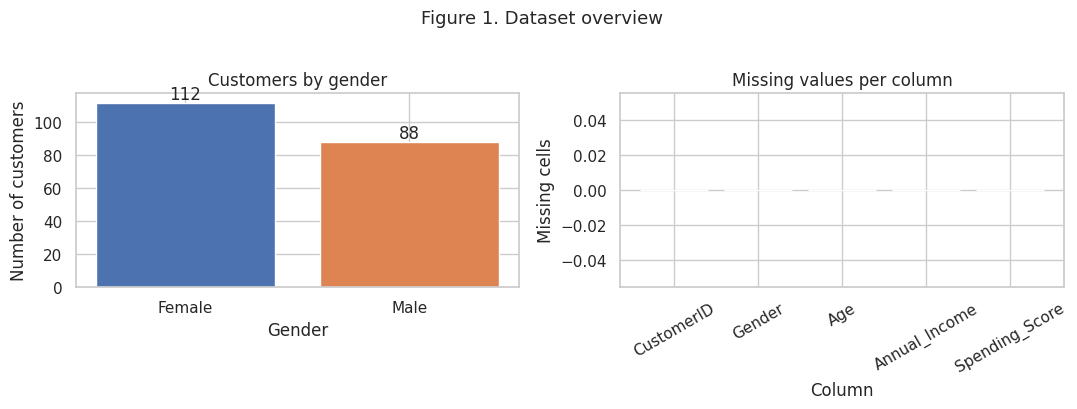

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

if "Gender" in df.columns:
    counts = df["Gender"].value_counts()
    bars = axes[0].bar(counts.index.astype(str), counts.values, color=["#4C72B0", "#DD8452", "#55A868"][:len(counts)])
    axes[0].bar_label(bars)
    axes[0].set_title("Customers by gender")
    axes[0].set_xlabel("Gender")
else:
    axes[0].bar(["All customers"], [len(df)], color="#4C72B0")
    axes[0].set_title("Number of records")
axes[0].set_ylabel("Number of customers")

missing_counts = df.isnull().sum()
axes[1].bar(missing_counts.index, missing_counts.values, color="#DD8452")
axes[1].set_title("Missing values per column")
axes[1].set_xlabel("Column")
axes[1].set_ylabel("Missing cells")
axes[1].tick_params(axis="x", rotation=30)

fig.suptitle("Figure 1. Dataset overview", fontsize=13, y=1.02)
save_and_show("fig01_dataset_overview")

### 2.4 Distribution of each feature
**Figure 2** shows how Age, Annual Income and Spending Score are spread out. One hump means most customers are alike. Several humps hint at different groups. A long tail means a few customers have unusually high (or low) values.

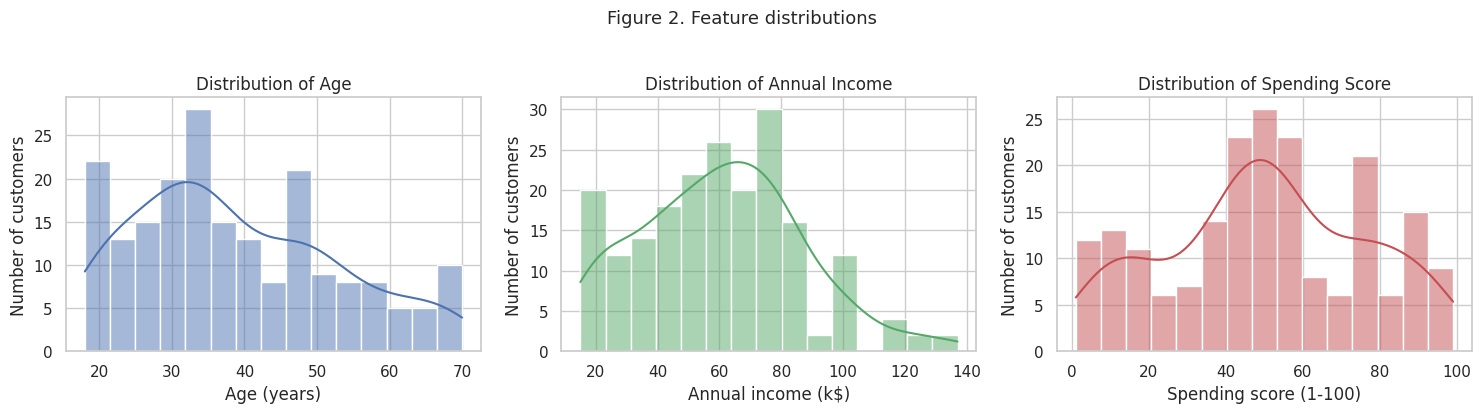

Skewness (0 = symmetric, positive = long right tail):
Age               0.49
Annual_Income     0.32
Spending_Score   -0.05
dtype: float64


In [45]:
numeric_cols = ["Age", "Annual_Income", "Spending_Score"]
nice_names = {"Age": "Age (years)",
              "Annual_Income": "Annual income (k$)",
              "Spending_Score": "Spending score (1-100)"}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, colour in zip(axes, numeric_cols, ["#4C72B0", "#55A868", "#C44E52"]):
    sns.histplot(df[col], bins=15, kde=True, color=colour, ax=ax)
    ax.set_title(f"Distribution of {col.replace('_', ' ')}")
    ax.set_xlabel(nice_names[col])
    ax.set_ylabel("Number of customers")
fig.suptitle("Figure 2. Feature distributions", fontsize=13, y=1.03)
save_and_show("fig02_distributions")

print("Skewness (0 = symmetric, positive = long right tail):")
print(df[numeric_cols].skew().round(2))

### 2.5 Outlier check
**Figure 3** uses box plots. The box holds the middle 50% of customers, the line inside is the median, and dots outside the whiskers are possible outliers (beyond 1.5 x IQR). We only remove an outlier if it looks like a data error. A rich customer is real information, so we keep it.

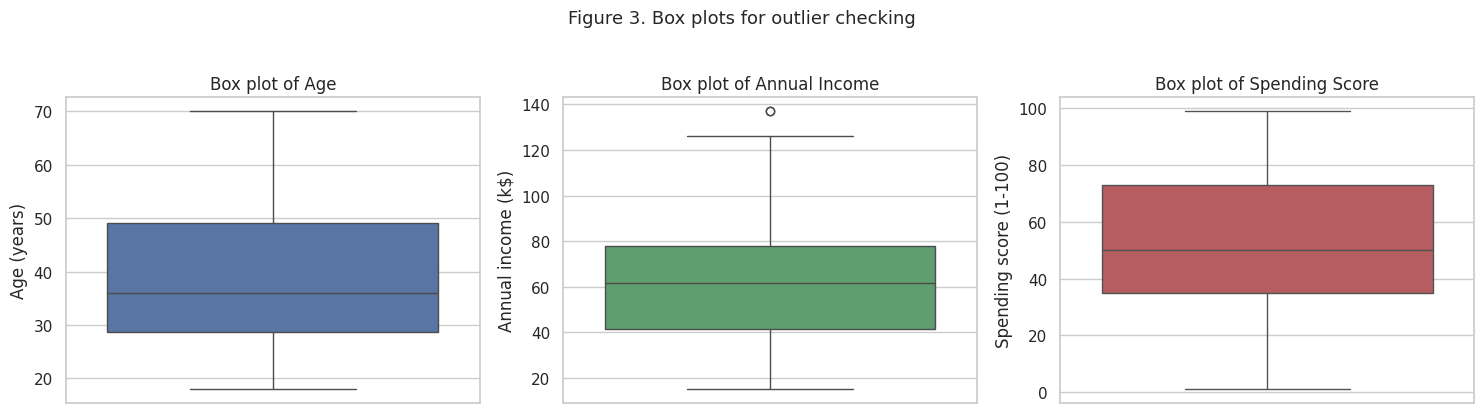

Outliers by the IQR rule:
  Age            : 0 outlier(s), allowed range -1.6 to 79.4
  Annual_Income  : 2 outlier(s), allowed range -13.2 to 132.8
  Spending_Score : 0 outlier(s), allowed range -22.6 to 130.4


In [46]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, colour in zip(axes, numeric_cols, ["#4C72B0", "#55A868", "#C44E52"]):
    sns.boxplot(y=df[col], color=colour, ax=ax)
    ax.set_title(f"Box plot of {col.replace('_', ' ')}")
    ax.set_ylabel(nice_names[col])
fig.suptitle("Figure 3. Box plots for outlier checking", fontsize=13, y=1.03)
save_and_show("fig03_boxplots")

print("Outliers by the IQR rule:")
for col in numeric_cols:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((df[col] < low) | (df[col] > high)).sum())
    print(f"  {col:15s}: {n_out} outlier(s), allowed range {low:.1f} to {high:.1f}")

### 2.6 How the features relate
**Figure 4** has one scatter plot per pair of features; every dot is a customer. Look for dense islands separated by empty gaps. Those islands are what a clustering algorithm tries to find.

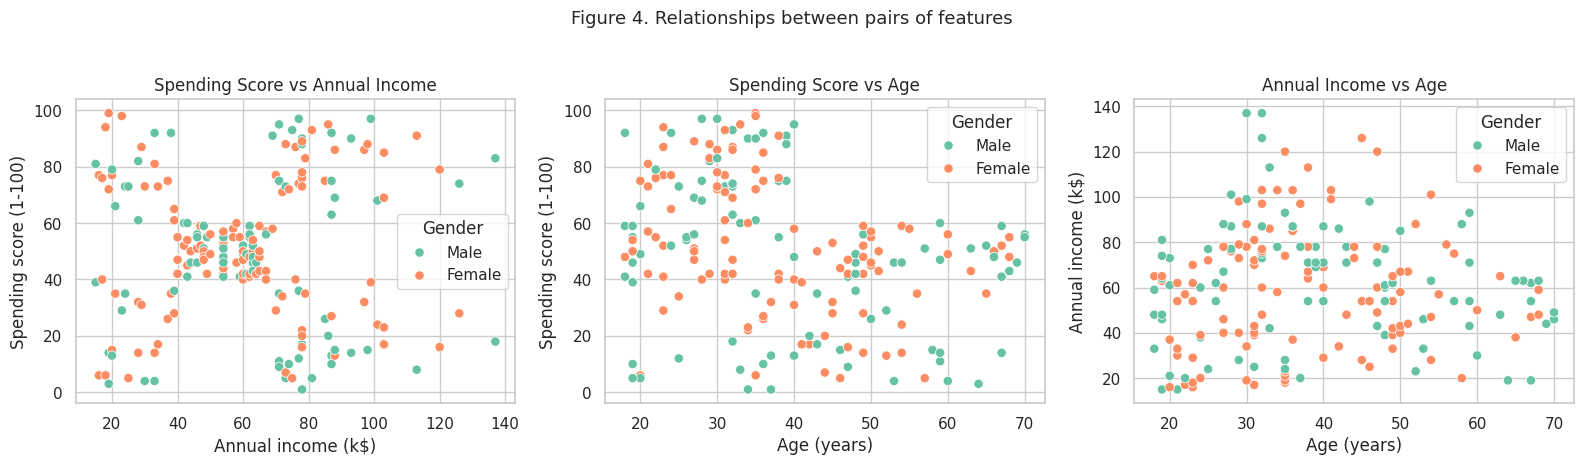

In [47]:
pairs = [("Annual_Income", "Spending_Score"),
         ("Age", "Spending_Score"),
         ("Age", "Annual_Income")]
hue_col = "Gender" if "Gender" in df.columns else None

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (xcol, ycol) in zip(axes, pairs):
    sns.scatterplot(data=df, x=xcol, y=ycol, hue=hue_col, palette="Set2",
                    s=45, edgecolor="white", ax=ax)
    ax.set_title(f"{ycol.replace('_', ' ')} vs {xcol.replace('_', ' ')}")
    ax.set_xlabel(nice_names[xcol])
    ax.set_ylabel(nice_names[ycol])
fig.suptitle("Figure 4. Relationships between pairs of features", fontsize=13, y=1.03)
save_and_show("fig04_feature_relationships")

### 2.7 Correlation
Correlation runs from -1 to +1 and tells us how strongly two features move together in a straight line. **Figure 5** is the heatmap. Values near 0 mean the features carry different information, which suits clustering. Keep in mind that a weak correlation does not mean "no pattern" (clusters are not straight lines), and correlation never proves cause and effect.

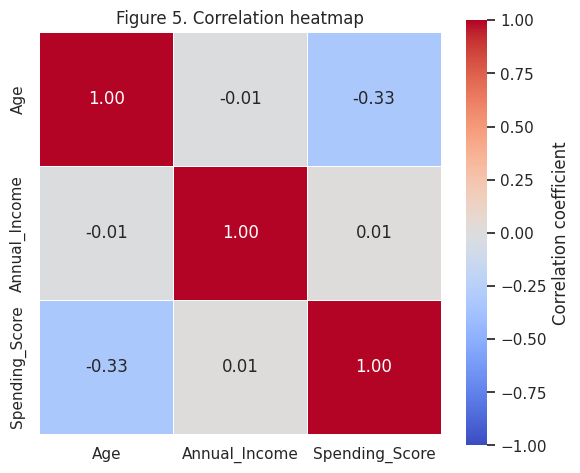

Strongest linear relationship: Age and Spending_Score (correlation = -0.33)


In [48]:
corr = df[numeric_cols].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"label": "Correlation coefficient"})
plt.title("Figure 5. Correlation heatmap")
save_and_show("fig05_correlation_heatmap")

# Print the strongest pair so we don't have to guess
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
strongest = upper.abs().idxmax()
print(f"Strongest linear relationship: {strongest[0]} and {strongest[1]} "
      f"(correlation = {corr.loc[strongest[0], strongest[1]]:.2f})")

## 3. Cleaning and scaling
### 3.1 Duplicates and missing values
Exact duplicate rows would count one customer twice, so they get dropped. Missing numbers (if any) are filled with the median, which is not pulled around by extreme values. If there are none, nothing changes. We avoid deleting rows because each row is a real customer.

In [49]:
rows_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicate rows removed: {rows_before - len(df)}")

# Make sure the numeric columns really are numbers
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Fill gaps with the median, only where there are gaps
for col in numeric_cols:
    n_missing = int(df[col].isnull().sum())
    if n_missing > 0:
        df[col] = df[col].fillna(df[col].median())
        print(f"Filled {n_missing} missing value(s) in {col} with the median.")

print("Missing values left:", int(df[numeric_cols].isnull().sum().sum()))
print("Rows available for clustering:", len(df))

Duplicate rows removed: 0
Missing values left: 0
Rows available for clustering: 200


### 3.2 Which features do we cluster on?
| Column | Used? | Why |
|---|---|---|
| `Annual_Income` | Yes | how much a customer *can* spend |
| `Spending_Score` | Yes | how much a customer *actually* spends (score from 1 to 100) |
| `Age` | Only to describe the groups later | keeps the model 2-D so we can plot and explain it |
| `Gender` | Only to describe the groups later | it is a category, and distance works best on measured numbers |
| `CustomerID` | No | just a label, no meaning for similarity |

In [50]:
FEATURES = ["Annual_Income", "Spending_Score"]
X = df[FEATURES].copy()
print("Clustering on:", FEATURES)
display(X.head())

Clustering on: ['Annual_Income', 'Spending_Score']


   Annual_Income  Spending_Score
0             15              39
1             15              81
2             16               6
3             16              77
4             17              40

### 3.3 Scaling with StandardScaler
Both algorithms work with distances, so a feature with bigger numbers would dominate. `StandardScaler` rewrites every feature as `z = (x - mean) / std`, giving each one mean 0 and standard deviation 1.

The guideline says to fit scalers on training data only. That is for supervised projects with a train/test split. Clustering has no target and no test set, so we fit on the whole feature table.

**Figure 6** shows the data before and after scaling. The shape stays the same, only the axis numbers change.

After scaling the mean should be about 0 and std about 1:


      Annual_Income  Spending_Score
mean         -0.000          -0.000
std           1.003           1.003

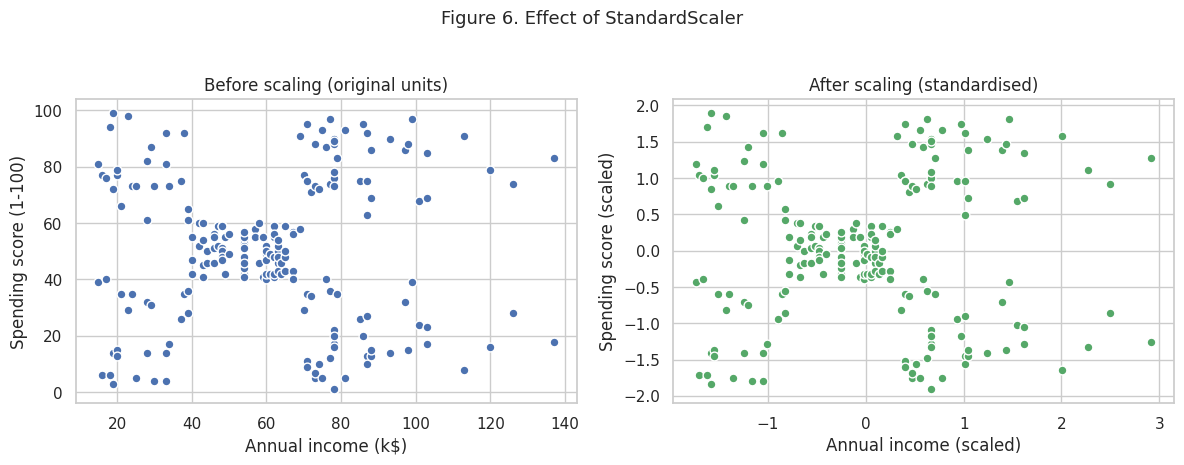

In [51]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)      # learn mean/std and transform in one go

check = pd.DataFrame(X_scaled, columns=FEATURES)
print("After scaling the mean should be about 0 and std about 1:")
display(check.describe().loc[["mean", "std"]].round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(X.iloc[:, 0], X.iloc[:, 1], s=40, color="#4C72B0", edgecolor="white")
axes[0].set_title("Before scaling (original units)")
axes[0].set_xlabel("Annual income (k$)")
axes[0].set_ylabel("Spending score (1-100)")
axes[1].scatter(X_scaled[:, 0], X_scaled[:, 1], s=40, color="#55A868", edgecolor="white")
axes[1].set_title("After scaling (standardised)")
axes[1].set_xlabel("Annual income (scaled)")
axes[1].set_ylabel("Spending score (scaled)")
fig.suptitle("Figure 6. Effect of StandardScaler", fontsize=13, y=1.03)
save_and_show("fig06_scaling")

## 4. K-Means
### 4.1 The idea
1. Pick the number of clusters **k**.
2. Drop k **centroids** (cluster centres) at starting positions. `k-means++` spreads them out smartly.
3. Give each customer to its nearest centroid (Euclidean, i.e. straight-line, distance).
4. Move each centroid to the average position of its customers.
5. Repeat steps 3 and 4 until the centroids stop moving.

A centroid is just the mean point of a cluster. Every customer ends up in exactly one cluster.

| Parameter | Meaning | Our value |
|---|---|---|
| `n_clusters` | how many clusters | chosen below from the data |
| `init` | how starting centroids are picked | `"k-means++"` |
| `n_init` | how many restarts (best run is kept) | `10` |
| `max_iter` | maximum rounds per run | `300` |
| `random_state` | seed for repeatable results | `42` |

### 4.2 How do we pick k?
* **Elbow Method:** WCSS (inertia) is the total squared distance from each customer to its own centroid. It always drops as k grows, so we look for the "elbow" where the drop slows down.
* **Silhouette Score:** from -1 to +1. Near +1 means well-separated clusters, near 0 means overlapping, negative means likely wrong cluster.

We test k = 1 to 10 (silhouette needs at least 2 clusters).

In [52]:
K_VALUES = list(range(1, 11))
inertias, silhouettes = [], {}

for k in K_VALUES:
    model = KMeans(n_clusters=k, init="k-means++", n_init=10,
                   max_iter=300, random_state=RANDOM_STATE)
    model.fit(X_scaled)
    inertias.append(model.inertia_)
    if k >= 2:
        silhouettes[k] = silhouette_score(X_scaled, model.labels_)

k_table = pd.DataFrame({
    "k": K_VALUES,
    "WCSS (inertia)": np.round(inertias, 2),
    "Silhouette": [np.nan] + [round(silhouettes[k], 4) for k in K_VALUES[1:]],
})
display(k_table)

    k  WCSS (inertia)  Silhouette
0   1          400.00         NaN
1   2          269.69      0.3213
2   3          157.70      0.4666
3   4          108.92      0.4939
4   5           65.57      0.5547
5   6           55.06      0.5399
6   7           44.86      0.5281
7   8           37.23      0.4552
8   9           32.39      0.4571
9  10           29.98      0.4432

### 4.3 Elbow and silhouette graphs
**Figure 7, left:** the elbow graph. **Right:** silhouette score per k, where the highest point is the best-separated clustering.

The code also estimates the elbow with a simple geometric rule (the point farthest from the straight line joining the first and last points). Our rule:

> **Final k = the k with the highest silhouette score**, with the elbow shown as supporting evidence. To try another value, set `K_OVERRIDE` in the next cell.

Elbow estimate:           k = 5
Best silhouette:          k = 5 (score 0.5547)
Final k used for K-Means: k = 5
Both methods agree, so the choice is solid.


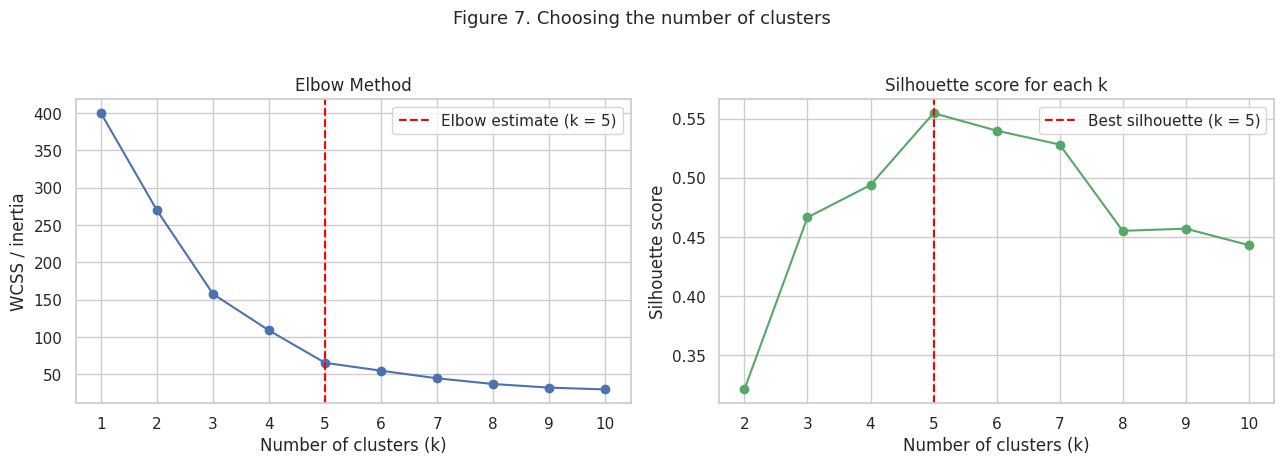

In [53]:
def find_elbow_decreasing(ks, values):
    # Elbow of a falling curve: farthest point below the line joining first and last point
    ks, values = np.array(ks, dtype=float), np.array(values, dtype=float)
    x = (ks - ks.min()) / (ks.max() - ks.min())
    y = (values - values.min()) / (values.max() - values.min())
    return int(ks[np.argmax((1 - x - y) / np.sqrt(2))])

elbow_k = find_elbow_decreasing(K_VALUES, inertias)
best_sil_k = max(silhouettes, key=silhouettes.get)

K_OVERRIDE = None     # put a number here (e.g. 4) to test another k; leave None for the data-driven choice
final_k = K_OVERRIDE if K_OVERRIDE is not None else best_sil_k

print(f"Elbow estimate:           k = {elbow_k}")
print(f"Best silhouette:          k = {best_sil_k} (score {silhouettes[best_sil_k]:.4f})")
print(f"Final k used for K-Means: k = {final_k}")
if elbow_k == best_sil_k:
    print("Both methods agree, so the choice is solid.")
else:
    print("The two methods differ; we go with silhouette and can discuss the gap in the report.")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(K_VALUES, inertias, marker="o", color="#4C72B0")
axes[0].axvline(elbow_k, color="red", linestyle="--", label=f"Elbow estimate (k = {elbow_k})")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("WCSS / inertia")
axes[0].set_xticks(K_VALUES)
axes[0].legend()

axes[1].plot(list(silhouettes.keys()), list(silhouettes.values()), marker="o", color="#55A868")
axes[1].axvline(best_sil_k, color="red", linestyle="--", label=f"Best silhouette (k = {best_sil_k})")
axes[1].set_title("Silhouette score for each k")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
axes[1].set_xticks(list(silhouettes.keys()))
axes[1].legend()

fig.suptitle("Figure 7. Choosing the number of clusters", fontsize=13, y=1.03)
save_and_show("fig07_elbow_silhouette")

### 4.4 Train the final K-Means model
`fit_predict()` trains the model and returns every customer's cluster number in one step. We save it as `KMeans_Cluster`.

In [54]:
kmeans = KMeans(n_clusters=final_k, init="k-means++", n_init=10,
                max_iter=300, random_state=RANDOM_STATE)
km_labels = kmeans.fit_predict(X_scaled)
df["KMeans_Cluster"] = km_labels

print(f"K-Means trained with k = {final_k}")
print(f"Iterations used by the best run: {kmeans.n_iter_}")
print(f"Final WCSS (inertia): {kmeans.inertia_:.2f}")
print("\nCustomers per cluster:")
print(df["KMeans_Cluster"].value_counts().sort_index())

K-Means trained with k = 5
Iterations used by the best run: 4
Final WCSS (inertia): 65.57

Customers per cluster:
KMeans_Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


### 4.5 See the K-Means clusters
**Figure 8** plots the customers in their original units, one colour per cluster. The black **X** marks are the centroids, converted back from scaled units with `inverse_transform()`. Clear colour blocks with an X in the middle mean a clean clustering.

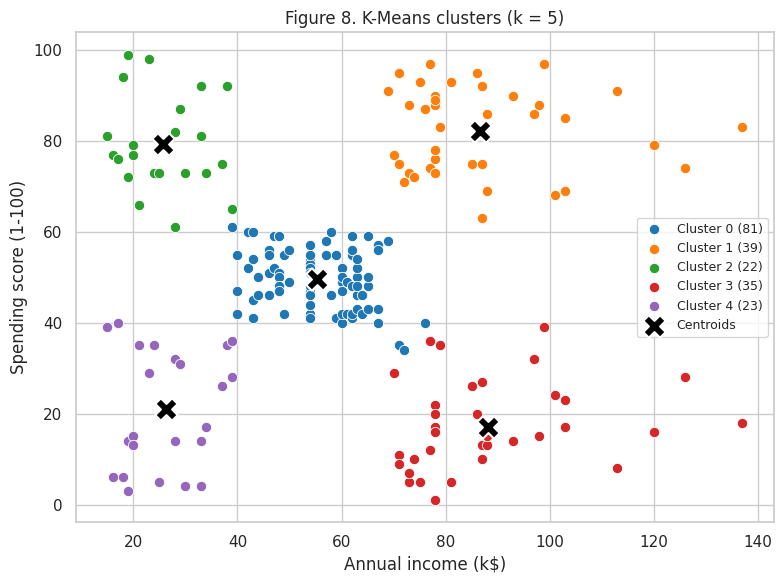

In [55]:
def plot_clusters(ax, points, labels, title, centroids=None):
    # Scatter plot coloured by cluster; label -1 (noise) is drawn as black crosses
    for lab in sorted(set(labels)):
        mask = labels == lab
        if lab == -1:
            ax.scatter(points[mask, 0], points[mask, 1], c="black", marker="x", s=50,
                       label=f"Noise ({mask.sum()})")
        else:
            ax.scatter(points[mask, 0], points[mask, 1], color=plt.cm.tab10(lab % 10), s=55,
                       edgecolor="white", linewidth=0.6, label=f"Cluster {lab} ({mask.sum()})")
    if centroids is not None:
        ax.scatter(centroids[:, 0], centroids[:, 1], c="black", marker="X", s=260,
                   edgecolor="white", linewidth=1.5, label="Centroids", zorder=5)
    ax.set_title(title)
    ax.set_xlabel("Annual income (k$)")
    ax.set_ylabel("Spending score (1-100)")
    ax.legend(loc="best", fontsize=9)

points = X.values                                                  # original units for plotting
centroids_original = scaler.inverse_transform(kmeans.cluster_centers_)

fig, ax = plt.subplots(figsize=(8, 6))
plot_clusters(ax, points, km_labels, f"Figure 8. K-Means clusters (k = {final_k})", centroids_original)
save_and_show("fig08_kmeans_clusters")

### 4.6 What does each cluster mean?
For every cluster we compute the average Age, Income and Spending Score. We also compare each centroid with the overall average: more than 0.5 standard deviations above is called *High*, more than 0.5 below is *Low*, otherwise *Average*. The labels come from the real data, not from us typing them in.

In [56]:
def level(z):
    # Turn a scaled centroid value into a word
    if z >= 0.5:
        return "High"
    if z <= -0.5:
        return "Low"
    return "Average"

def make_profile(data, label_col):
    # Average behaviour of every cluster
    grouped = data.groupby(label_col)
    profile = pd.DataFrame({
        "Customers": grouped.size(),
        "Share_%": (grouped.size() / len(data) * 100).round(1),
        "Avg_Age": grouped["Age"].mean().round(1),
        "Avg_Income_k$": grouped["Annual_Income"].mean().round(1),
        "Avg_Spending": grouped["Spending_Score"].mean().round(1),
    })
    if "Gender" in data.columns:
        profile["Female_%"] = grouped["Gender"].apply(
            lambda s: round(s.astype(str).str.lower().str.startswith("f").mean() * 100, 1))
    return profile

km_profile = make_profile(df, "KMeans_Cluster")

km_names = {}
for c in range(final_k):
    km_names[c] = f"{level(kmeans.cluster_centers_[c, 0])} income / {level(kmeans.cluster_centers_[c, 1])} spending"
km_profile.insert(0, "Segment type", [km_names[c] for c in km_profile.index])
display(km_profile)

meaning = {
    ("High", "High"): "Premium shoppers. They earn a lot and spend a lot, ideal for loyalty and premium offers.",
    ("High", "Low"): "Careful high earners. They could spend more, so personal offers may help.",
    ("Low", "High"): "Enthusiastic spenders. They spend a lot for their income and respond to deals.",
    ("Low", "Low"): "Budget-conscious customers. Low income and low spending.",
    ("Average", "Average"): "Typical mid-range customers.",
}
print("\nPlain-language reading of each cluster:")
for c in range(final_k):
    il, sl = level(kmeans.cluster_centers_[c, 0]), level(kmeans.cluster_centers_[c, 1])
    text = meaning.get((il, sl), f"Mixed profile: {il.lower()} income and {sl.lower()} spending.")
    print(f"- Cluster {c} ({km_names[c]}, {int(km_profile.loc[c, 'Customers'])} customers): {text}")

                                     Segment type  Customers  Share_%  \
KMeans_Cluster                                                          
0               Average income / Average spending         81     40.5   
1                     High income / High spending         39     19.5   
2                      Low income / High spending         22     11.0   
3                      High income / Low spending         35     17.5   
4                       Low income / Low spending         23     11.5   

                Avg_Age  Avg_Income_k$  Avg_Spending  Female_%  
KMeans_Cluster                                                  
0                  42.7           55.3          49.5      59.3  
1                  32.7           86.5          82.1      53.8  
2                  25.3           25.7          79.4      59.1  
3                  41.1           88.2          17.1      45.7  
4                  45.2           26.3          20.9      60.9  


Plain-language reading of each cluster:
- Cluster 0 (Average income / Average spending, 81 customers): Typical mid-range customers.
- Cluster 1 (High income / High spending, 39 customers): Premium shoppers. They earn a lot and spend a lot, ideal for loyalty and premium offers.
- Cluster 2 (Low income / High spending, 22 customers): Enthusiastic spenders. They spend a lot for their income and respond to deals.
- Cluster 3 (High income / Low spending, 35 customers): Careful high earners. They could spend more, so personal offers may help.
- Cluster 4 (Low income / Low spending, 23 customers): Budget-conscious customers. Low income and low spending.


## 5. DBSCAN
### 5.1 The idea
DBSCAN looks for **crowded regions** separated by **empty regions**, so we don't tell it the number of clusters. It has two parameters:

* **`eps`**: the radius of the neighbourhood around each point.
* **`min_samples`**: how many points (itself included) must sit inside that radius for the area to count as crowded.

| Point type | Meaning |
|---|---|
| **Core point** | has at least `min_samples` points within `eps` |
| **Border point** | not core, but within `eps` of a core point |
| **Noise point** | neither of the above, labelled **-1**, belongs to no cluster |

### 5.2 Picking eps and min_samples with analysis
1. **k-distance graph:** for each customer we measure the distance to its `min_samples`-th nearest neighbour and sort the values. The bend ("knee") hints at a good `eps`. A common starting value for `min_samples` is 2 x number of features, which is 4 here.
2. **Grid search:** we try many `eps` and `min_samples` combinations and record clusters, noise % and silhouette (on non-noise points, explained in Section 6).

The k-distance knee suggests eps of about 0.31 (min_samples = 4)


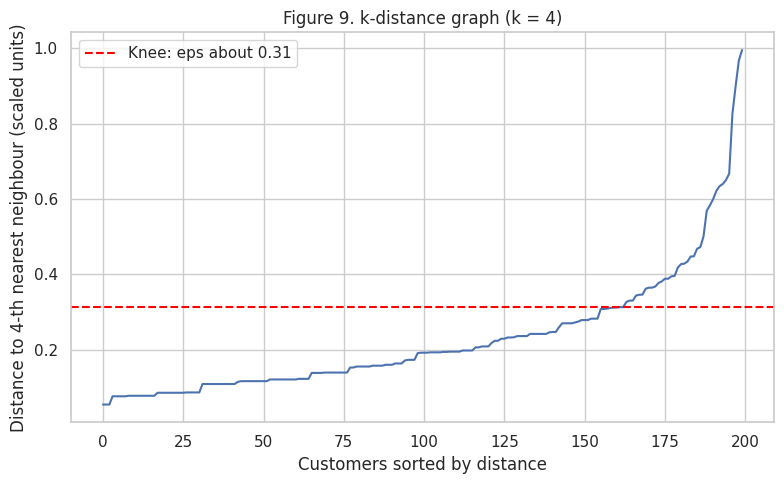

In [57]:
MS_FOR_KDIST = 2 * len(FEATURES)       # rule of thumb: 2 x number of features

nn = NearestNeighbors(n_neighbors=MS_FOR_KDIST).fit(X_scaled)
distances, _ = nn.kneighbors(X_scaled)          # the first neighbour of a point is itself
k_distances = np.sort(distances[:, -1])

def find_knee_increasing(values):
    # Knee of a rising curve: farthest point below the line joining first and last point
    values = np.array(values, dtype=float)
    x = np.linspace(0, 1, len(values))
    y = (values - values.min()) / (values.max() - values.min())
    return int(np.argmax((x - y) / np.sqrt(2)))

eps_suggestion = float(k_distances[find_knee_increasing(k_distances)])
print(f"The k-distance knee suggests eps of about {eps_suggestion:.2f} (min_samples = {MS_FOR_KDIST})")

plt.figure(figsize=(8, 5))
plt.plot(k_distances, color="#4C72B0")
plt.axhline(eps_suggestion, color="red", linestyle="--", label=f"Knee: eps about {eps_suggestion:.2f}")
plt.title(f"Figure 9. k-distance graph (k = {MS_FOR_KDIST})")
plt.xlabel("Customers sorted by distance")
plt.ylabel(f"Distance to {MS_FOR_KDIST}-th nearest neighbour (scaled units)")
plt.legend()
save_and_show("fig09_k_distance")

**Reading Figure 9:** the curve stays low for most customers (crowded areas) and shoots up for the few isolated ones. The bend marks where "crowded" turns into "isolated". It's only a hint, which is why we also run the grid search.

In [58]:
eps_values = [round(float(e), 2) for e in np.arange(0.10, 0.81, 0.05)]
min_samples_values = [3, 4, 5, 6, 8, 10]

def safe_silhouette(data, labels):
    # Silhouette only makes sense with 2 or more clusters
    n_labels = len(set(labels))
    if n_labels < 2 or n_labels > len(data) - 1:
        return np.nan
    return silhouette_score(data, labels)

records = []
for ms in min_samples_values:
    for eps in eps_values:
        labels_try = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        n_clusters = len(set(labels_try)) - (1 if -1 in labels_try else 0)
        n_noise = int((labels_try == -1).sum())
        keep = labels_try != -1                       # non-noise points only
        sil = safe_silhouette(X_scaled[keep], labels_try[keep]) if keep.sum() > 2 else np.nan
        records.append({"eps": eps, "min_samples": ms, "Clusters": n_clusters,
                        "Noise_points": n_noise,
                        "Noise_%": round(n_noise / len(X_scaled) * 100, 1),
                        "Silhouette_non_noise": sil})

grid = pd.DataFrame(records)
print(f"{len(grid)} combinations tested. Top 10 by silhouette:")
display(grid.sort_values("Silhouette_non_noise", ascending=False).head(10).round(4))

90 combinations tested. Top 10 by silhouette:


     eps  min_samples  Clusters  Noise_points  Noise_%  Silhouette_non_noise
78  0.25           10         2           111     55.5                0.7287
45  0.10            6         3           173     86.5                0.6189
17  0.20            4         5            73     36.5                0.6173
47  0.20            6         4            95     47.5                0.6138
79  0.30           10         4            88     44.0                0.6073
62  0.20            8         2           116     58.0                0.6027
65  0.35            8         4            55     27.5                0.5994
81  0.40           10         4            51     25.5                0.5972
63  0.25            8         5            79     39.5                0.5947
64  0.30            8         5            72     36.0                0.5926

### 5.3 Choosing the final setting
The highest silhouette alone would be unfair: it ignores noise, so a setting that throws away half the customers can look "perfect". Our rule:

1. Keep settings with **2 to 10 clusters** and **noise of at most 10%**.
2. Pick the one with the **highest silhouette** (ties: less noise).
3. If nothing qualifies, relax the noise limit to 20%, then 35%.
4. Still nothing? Take the setting with 2+ clusters and the least noise.
5. If DBSCAN never finds 2 clusters, use the defaults (`eps = 0.5`, `min_samples = 5`) and say so honestly.

In [59]:
def choose_dbscan(grid_table):
    for max_noise in [10, 20, 35]:
        ok = grid_table[(grid_table["Clusters"] >= 2) & (grid_table["Clusters"] <= 10) &
                        (grid_table["Noise_%"] <= max_noise) &
                        (grid_table["Silhouette_non_noise"].notna())]
        if len(ok) > 0:
            best = ok.sort_values(["Silhouette_non_noise", "Noise_%"], ascending=[False, True]).iloc[0]
            return best["eps"], int(best["min_samples"]), f"best silhouette with noise <= {max_noise}%"
    two_plus = grid_table[grid_table["Clusters"] >= 2]
    if len(two_plus) > 0:
        best = two_plus.sort_values(["Noise_%", "Clusters"], ascending=[True, False]).iloc[0]
        return best["eps"], int(best["min_samples"]), "least noise among settings with 2+ clusters"
    return 0.5, 5, "defaults (DBSCAN never found 2 clusters in the grid)"

best_eps, best_ms, rule_used = choose_dbscan(grid)
print(f"Selected eps = {best_eps}, min_samples = {best_ms}")
print(f"Rule used: {rule_used}")

Selected eps = 0.35, min_samples = 3
Rule used: best silhouette with noise <= 10%


**Figure 10** shows how the number of clusters and the noise % change with `eps` for the chosen `min_samples`. A tiny `eps` turns almost everything into noise, a huge one merges everything into a single cluster. The chosen value (dashed line) should sit in a stable middle zone.

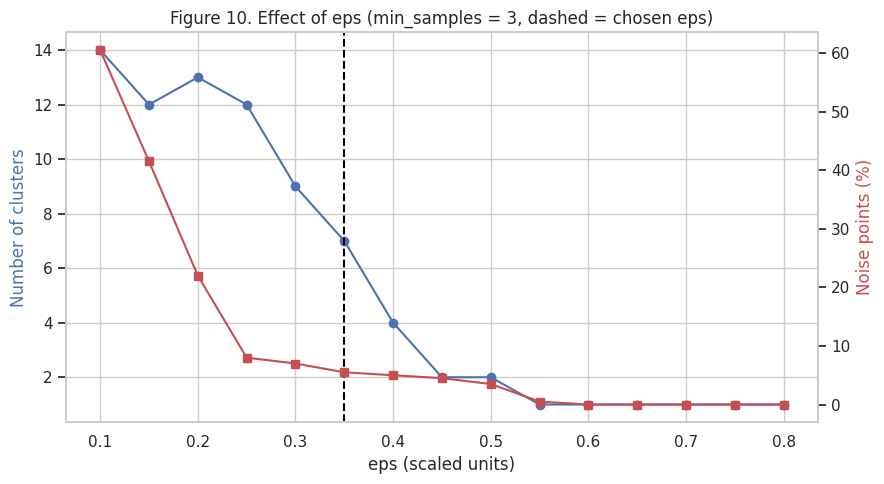

In [60]:
subset = grid[grid["min_samples"] == best_ms]

fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(subset["eps"], subset["Clusters"], marker="o", color="#4C72B0")
ax1.set_xlabel("eps (scaled units)")
ax1.set_ylabel("Number of clusters", color="#4C72B0")
ax2 = ax1.twinx()
ax2.plot(subset["eps"], subset["Noise_%"], marker="s", color="#C44E52")
ax2.set_ylabel("Noise points (%)", color="#C44E52")
ax2.grid(False)
ax1.axvline(best_eps, color="black", linestyle="--")
ax1.set_title(f"Figure 10. Effect of eps (min_samples = {best_ms}, dashed = chosen eps)")
save_and_show("fig10_eps_effect")

### 5.4 Train the final DBSCAN model
`fit_predict()` gives `0, 1, 2...` for clusters and `-1` for noise. We then count clusters, noise and the core/border/noise split.

In [61]:
dbscan = DBSCAN(eps=best_eps, min_samples=best_ms)
db_labels = dbscan.fit_predict(X_scaled)
df["DBSCAN_Cluster"] = db_labels

db_n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
db_n_noise = int((db_labels == -1).sum())
db_noise_pct = db_n_noise / len(db_labels) * 100

core_mask = np.zeros(len(db_labels), dtype=bool)
core_mask[dbscan.core_sample_indices_] = True
n_core = int(core_mask.sum())
n_border = len(db_labels) - n_core - db_n_noise

print(f"eps = {best_eps}, min_samples = {best_ms}")
print(f"Clusters found : {db_n_clusters}")
print(f"Noise points   : {db_n_noise} ({db_noise_pct:.1f}% of customers)")
print(f"Core / border / noise: {n_core} / {n_border} / {db_n_noise}")
print("\nCustomers per DBSCAN label (-1 = noise):")
print(df["DBSCAN_Cluster"].value_counts().sort_index())

if db_n_clusters == 0:
    print("\nWARNING: everything was labelled noise. No dense region was found with these settings.")
elif db_n_clusters == 1:
    print("\nNOTE: only ONE cluster was found, so DBSCAN did not separate customer groups here.")

eps = 0.35, min_samples = 3
Clusters found : 7
Noise points   : 11 (5.5% of customers)
Core / border / noise: 184 / 5 / 11

Customers per DBSCAN label (-1 = noise):
DBSCAN_Cluster
-1    11
 0     7
 1    18
 2    12
 3     3
 4    89
 5    32
 6    28
Name: count, dtype: int64


### 5.5 See the DBSCAN clusters
**Figure 11** shows the DBSCAN result in original units. Black crosses are noise, meaning customers outside any dense region. Compare it with the K-Means picture and notice where the crosses sit (usually at the edges or in sparse areas).

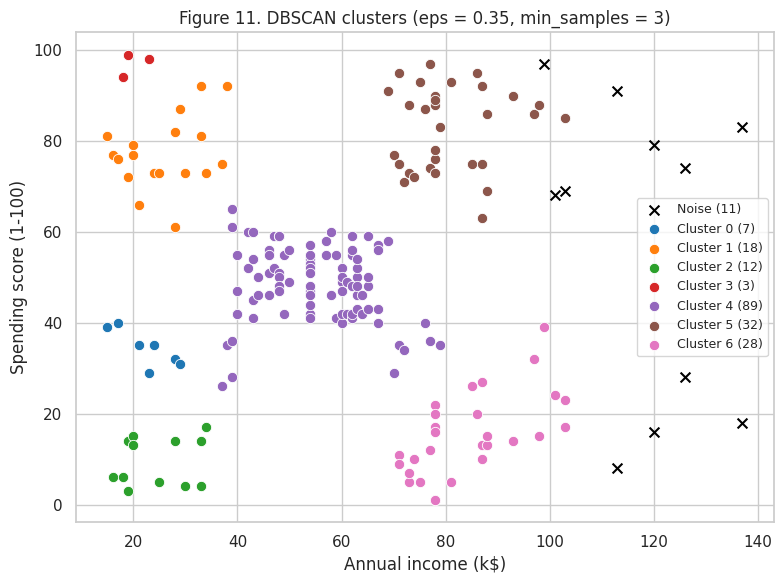

In [62]:
fig, ax = plt.subplots(figsize=(8, 6))
plot_clusters(ax, points, db_labels,
              f"Figure 11. DBSCAN clusters (eps = {best_eps}, min_samples = {best_ms})")
save_and_show("fig11_dbscan_clusters")

### 5.6 What do the DBSCAN clusters mean?
Same profile table as before. The row labelled **-1** describes the noise customers.

In [63]:
db_profile = make_profile(df, "DBSCAN_Cluster")
display(db_profile)

if db_n_clusters >= 1:
    print("Each DBSCAN cluster compared with the overall average:")
    for lab in sorted(set(db_labels)):
        if lab == -1:
            continue
        centre = X_scaled[db_labels == lab].mean(axis=0)
        print(f"- Cluster {lab}: {int((db_labels == lab).sum())} customers, "
              f"{level(centre[0])} income / {level(centre[1])} spending")

                Customers  Share_%  Avg_Age  Avg_Income_k$  Avg_Spending  \
DBSCAN_Cluster                                                             
-1                     11      5.5     34.7          117.7          57.4   
 0                      7      3.5     36.7           22.4          34.4   
 1                     18      9.0     24.4           25.9          77.2   
 2                     12      6.0     48.8           24.6           9.6   
 3                      3      1.5     31.0           20.0          97.0   
 4                     89     44.5     42.8           55.0          48.3   
 5                     32     16.0     32.8           80.5          82.6   
 6                     28     14.0     41.2           84.5          15.3   

                Female_%  
DBSCAN_Cluster            
-1                  45.5  
 0                  57.1  
 1                  50.0  
 2                  58.3  
 3                 100.0  
 4                  60.7  
 5                  56.

Each DBSCAN cluster compared with the overall average:
- Cluster 0: 7 customers, Low income / Low spending
- Cluster 1: 18 customers, Low income / High spending
- Cluster 2: 12 customers, Low income / Low spending
- Cluster 3: 3 customers, Low income / High spending
- Cluster 4: 89 customers, Average income / Average spending
- Cluster 5: 32 customers, High income / High spending
- Cluster 6: 28 customers, High income / Low spending


## 6. K-Means vs DBSCAN
### 6.1 Fair evaluation
* This is **unsupervised learning**: there is no answer column, so accuracy, precision and recall do **not** apply. We use silhouette score and visual checks instead.
* **K-Means:** every customer has a cluster, so silhouette is computed on all customers.
* **DBSCAN:** noise (-1) is not a real cluster, so we compute silhouette on **non-noise points only**. It is only defined when DBSCAN finds at least 2 clusters.
* For a fair side-by-side, we also compute K-Means silhouette on the **same non-noise points** DBSCAN kept.

DBSCAN's score ignores the customers it rejected, so always read it together with the noise %.

In [64]:
non_noise = db_labels != -1

km_sil_all = safe_silhouette(X_scaled, km_labels)
km_sil_same = safe_silhouette(X_scaled[non_noise], km_labels[non_noise]) if non_noise.sum() > 2 else np.nan
db_sil = safe_silhouette(X_scaled[non_noise], db_labels[non_noise]) if non_noise.sum() > 2 else np.nan

def size_text(labels):
    counts = pd.Series(labels).value_counts().sort_index()
    return ", ".join([("Noise" if k == -1 else f"C{k}") + f": {v}" for k, v in counts.items()])

def fmt(value):
    return "not defined" if pd.isna(value) else f"{value:.4f}"

comparison = pd.DataFrame({
    "K-Means": {
        "Parameters": f"k={final_k}, init=k-means++, n_init=10, random_state=42",
        "Number of clusters": final_k,
        "Noise points": 0,
        "Noise %": "0.0",
        "Silhouette (all points)": fmt(km_sil_all),
        "Silhouette (same non-noise points as DBSCAN)": fmt(km_sil_same),
        "Cluster sizes": size_text(km_labels),
    },
    "DBSCAN": {
        "Parameters": f"eps={best_eps}, min_samples={best_ms}",
        "Number of clusters": db_n_clusters,
        "Noise points": db_n_noise,
        "Noise %": f"{db_noise_pct:.1f}",
        "Silhouette (all points)": "not valid (noise has no cluster)",
        "Silhouette (same non-noise points as DBSCAN)": fmt(db_sil),
        "Cluster sizes": size_text(db_labels),
    },
})
pd.set_option("display.max_colwidth", 120)
display(comparison)

                                                                                      K-Means  \
Parameters                                    k=5, init=k-means++, n_init=10, random_state=42   
Number of clusters                                                                          5   
Noise points                                                                                0   
Noise %                                                                                   0.0   
Silhouette (all points)                                                                0.5547   
Silhouette (same non-noise points as DBSCAN)                                           0.5777   
Cluster sizes                                          C0: 81, C1: 39, C2: 22, C3: 35, C4: 23   

                                                                                                       DBSCAN  
Parameters                                                                            eps=0.35, min_samples=3  

### 6.2 Side-by-side qualities
| Aspect | K-Means | DBSCAN |
|---|---|---|
| Number of clusters in advance | Needed (Elbow + Silhouette) | Not needed |
| Main parameters | `n_clusters`, `n_init`, `random_state` | `eps`, `min_samples` |
| Cluster shape | Best for round, similar-sized groups | Any shape |
| Outliers | Forces every point into a cluster | Marks them as noise (-1) |
| Strengths | Simple, fast, everyone gets a segment, easy to explain | Finds odd shapes, spots unusual customers |
| Weaknesses | Sensitive to outliers and start points | Sensitive to `eps`/`min_samples`, struggles with uneven density, may leave many customers unassigned |

### 6.3 Comparison charts
**Figure 12** puts both results next to each other. **Figure 13** compares cluster sizes and silhouette scores.

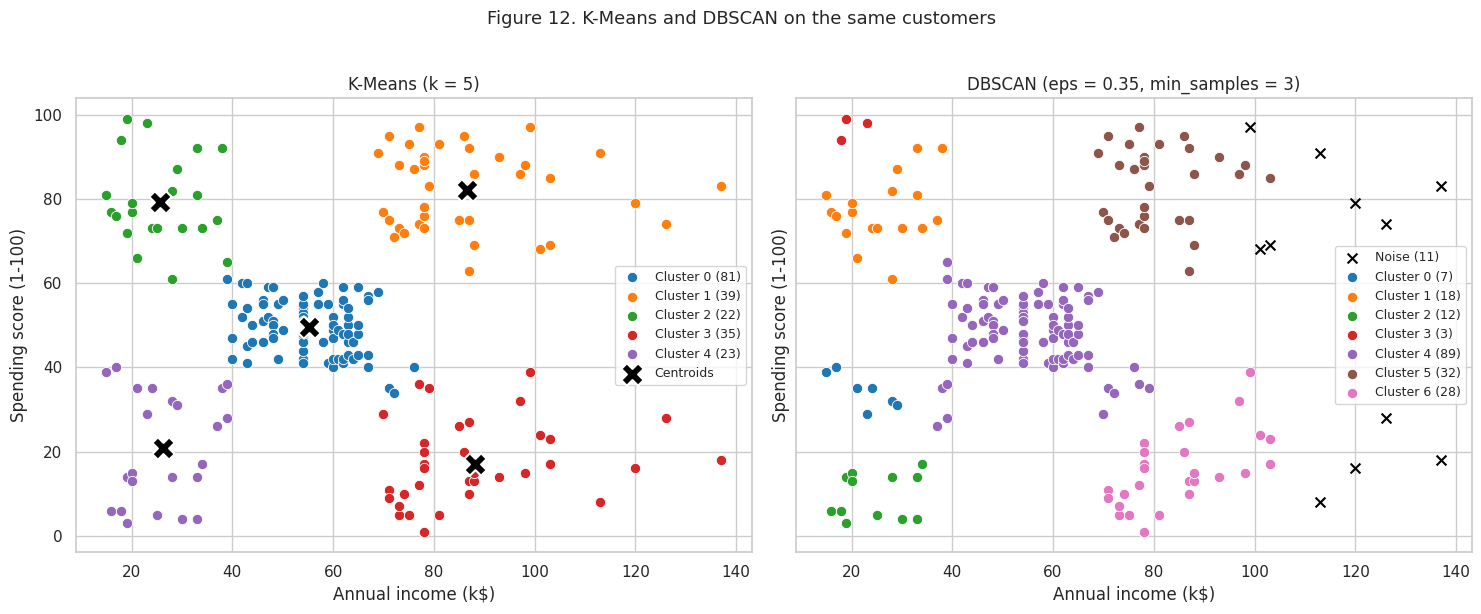

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
plot_clusters(axes[0], points, km_labels, f"K-Means (k = {final_k})", centroids_original)
plot_clusters(axes[1], points, db_labels, f"DBSCAN (eps = {best_eps}, min_samples = {best_ms})")
fig.suptitle("Figure 12. K-Means and DBSCAN on the same customers", fontsize=13, y=1.02)
save_and_show("fig12_side_by_side")

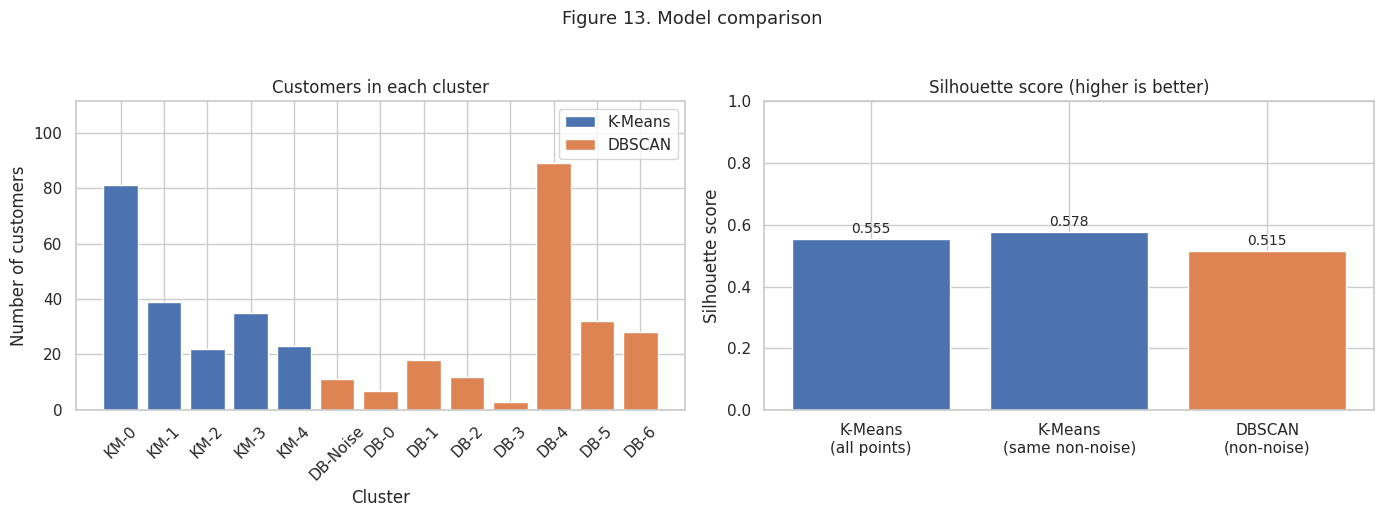

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: how many customers in each cluster
km_counts = pd.Series(km_labels).value_counts().sort_index()
db_counts = pd.Series(db_labels).value_counts().sort_index()
x_km = [f"KM-{c}" for c in km_counts.index]
x_db = [("DB-Noise" if c == -1 else f"DB-{c}") for c in db_counts.index]
axes[0].bar(x_km, km_counts.values, color="#4C72B0", label="K-Means")
axes[0].bar(x_db, db_counts.values, color="#DD8452", label="DBSCAN")
axes[0].set_title("Customers in each cluster")
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("Number of customers")
axes[0].tick_params(axis="x", rotation=45)
axes[0].set_ylim(0, max(km_counts.max(), db_counts.max()) * 1.25)   # room for the legend
axes[0].legend(loc="upper right")

# Right: silhouette scores (undefined ones are drawn as 0 and labelled)
names = ["K-Means\n(all points)", "K-Means\n(same non-noise)", "DBSCAN\n(non-noise)"]
vals = [km_sil_all, km_sil_same, db_sil]
bars = axes[1].bar(names, [0 if pd.isna(v) else v for v in vals],
                   color=["#4C72B0", "#4C72B0", "#DD8452"])
for bar, v in zip(bars, vals):
    label = "not defined" if pd.isna(v) else f"{v:.3f}"
    axes[1].text(bar.get_x() + bar.get_width() / 2, max(bar.get_height(), 0) + 0.01, label,
                 ha="center", va="bottom", fontsize=10)
axes[1].set_title("Silhouette score (higher is better)")
axes[1].set_ylabel("Silhouette score")
axes[1].set_ylim(0, 1)

fig.suptitle("Figure 13. Model comparison", fontsize=13, y=1.03)
save_and_show("fig13_model_comparison")

**Reading Figure 13:** on the left, evenly sized bars mean customers are split into several useful segments, while one huge bar plus a tall noise bar means the algorithm failed to separate groups. On the right, taller silhouette bars mean better-separated clusters, but DBSCAN's bar must always be judged together with its noise %.

### 6.4 The verdict
A simple, open rule decides, and the facts are printed first:

* DBSCAN is *usable* if it found **3 or more clusters** with **at most 10% noise**.
* If it is usable and its silhouette beats K-Means on the same points by more than 0.05, DBSCAN wins.
* Otherwise K-Means wins, because it gives every customer a segment with a clear centroid.

In [67]:
print("FACTS")
print(f" - K-Means: {final_k} clusters, 0 noise, silhouette (all points) = {fmt(km_sil_all)}")
print(f" - DBSCAN: {db_n_clusters} cluster(s), {db_n_noise} noise points ({db_noise_pct:.1f}%), "
      f"silhouette (non-noise) = {fmt(db_sil)}")
print(f" - K-Means silhouette on the same non-noise points = {fmt(km_sil_same)}")

dbscan_usable = (db_n_clusters >= 3) and (db_noise_pct <= 10)
clearly_better = (not pd.isna(db_sil)) and (not pd.isna(km_sil_same)) and (db_sil > km_sil_same + 0.05)

if dbscan_usable and clearly_better:
    verdict = "DBSCAN"
    why = "It found several clusters with little noise and a clearly higher silhouette than K-Means on the same points."
elif dbscan_usable:
    verdict = "K-Means"
    why = "Both give usable segments of similar quality, so K-Means wins on simplicity and because it covers every customer."
else:
    verdict = "K-Means"
    reasons = []
    if db_n_clusters == 0:
        reasons.append("DBSCAN found no clusters (everything was noise)")
    elif db_n_clusters < 3:
        reasons.append(f"DBSCAN found only {db_n_clusters} cluster(s), too coarse for customer segmentation")
    if db_noise_pct > 10:
        reasons.append(f"DBSCAN left {db_noise_pct:.1f}% of customers without a segment")
    why = "; ".join(reasons) + ". K-Means gives every customer a segment."

print(f"\nVERDICT: {verdict} is more suitable for this dataset.")
print("REASON :", why)
print("\nCheck this against Figure 12 and explain it in your own words.")

FACTS
 - K-Means: 5 clusters, 0 noise, silhouette (all points) = 0.5547
 - DBSCAN: 7 cluster(s), 11 noise points (5.5%), silhouette (non-noise) = 0.5154
 - K-Means silhouette on the same non-noise points = 0.5777

VERDICT: K-Means is more suitable for this dataset.
REASON : Both give usable segments of similar quality, so K-Means wins on simplicity and because it covers every customer.

Check this against Figure 12 and explain it in your own words.


## 7. Final summary
This cell prints a copy-ready results table, so you can use the **actual** numbers in your report and slides. It also saves:

* `customer_segments.csv`: the data with both cluster labels
* `clustering_results_summary.csv`: the results table
* `figures.zip`: all figures as PNG

You can download them from the **Files** panel on the left of Colab.

In [68]:
summary = pd.DataFrame([
    {"Algorithm": "K-Means", "Parameters": f"k={final_k}", "Clusters": final_k,
     "Noise points": 0, "Noise %": 0.0,
     "Silhouette": None if pd.isna(km_sil_all) else round(km_sil_all, 4),
     "Silhouette note": "all customers"},
    {"Algorithm": "DBSCAN", "Parameters": f"eps={best_eps}, min_samples={best_ms}", "Clusters": db_n_clusters,
     "Noise points": db_n_noise, "Noise %": round(db_noise_pct, 1),
     "Silhouette": None if pd.isna(db_sil) else round(db_sil, 4),
     "Silhouette note": "non-noise customers only"},
])
print("RESULTS SUMMARY")
display(summary)

print(f"Customers used: {len(df)} | Features: {FEATURES}")
print(f"Elbow estimate: {elbow_k} | Best silhouette k: {best_sil_k} | Final k: {final_k}")
print(f"Verdict: {verdict}")

df.to_csv("customer_segments.csv", index=False)
summary.to_csv("clustering_results_summary.csv", index=False)
shutil.make_archive("figures", "zip", "figures")
print("\nSaved: customer_segments.csv, clustering_results_summary.csv, figures.zip")

RESULTS SUMMARY


  Algorithm               Parameters  Clusters  Noise points  Noise %  \
0   K-Means                      k=5         5             0      0.0   
1    DBSCAN  eps=0.35, min_samples=3         7            11      5.5   

   Silhouette           Silhouette note  
0      0.5547             all customers  
1      0.5154  non-noise customers only  

Customers used: 200 | Features: ['Annual_Income', 'Spending_Score']
Elbow estimate: 5 | Best silhouette k: 5 | Final k: 5
Verdict: K-Means

Saved: customer_segments.csv, clustering_results_summary.csv, figures.zip


### Reproducibility
* Seed: `RANDOM_STATE = 42`. DBSCAN has no randomness for a fixed dataset.
* Data: Kaggle `shwetabh123/mall-customers`, downloaded with `kagglehub`.
* Libraries: pandas, NumPy, matplotlib, seaborn, scikit-learn (Colab's default versions).

### Limitations
* Small dataset from a single source, so the segments may not carry over to other malls.
* Only two features were clustered. Age and gender were used just to describe the groups.
* Spending Score is a mall-assigned score, not real purchase amounts.
* Clustering has no ground truth, so quality is judged by silhouette, visuals and business sense, not accuracy.
* DBSCAN depends heavily on `eps` and `min_samples`.

### Future work
Add Age as a third feature, try Hierarchical or Gaussian Mixture clustering, validate on another dataset, and build a small app that assigns a new customer to a segment.